In [8]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

### Importing CSV with data for boise and snake basins

In [15]:
dfB = pd.read_csv("data/snotel_Boise.csv")
print(dfB.head())

dfS = pd.read_csv("data/snotel_snake.csv")
print(dfS.head())

dfP = pd.read_csv("data/usgs_flow_twin_springs_moose.csv")

   water_year  day_of_water_year        date  site_id       site_name  \
0        1979                  1  1978-10-01      306  Atlanta Summit   
1        1979                  2  1978-10-02      306  Atlanta Summit   
2        1979                  3  1978-10-03      306  Atlanta Summit   
3        1979                  4  1978-10-04      306  Atlanta Summit   
4        1979                  5  1978-10-05      306  Atlanta Summit   

                basin state  PRCP  PREC  RHUMV  ...  TOBS_ord1_2  WTEQ  \
0  Middle Boise River    ID   NaN   NaN    NaN  ...          NaN   NaN   
1  Middle Boise River    ID   NaN   NaN    NaN  ...          NaN   NaN   
2  Middle Boise River    ID   NaN   NaN    NaN  ...          NaN   NaN   
3  Middle Boise River    ID   NaN   NaN    NaN  ...          NaN   NaN   
4  Middle Boise River    ID   NaN   NaN    NaN  ...          NaN   NaN   

   WTEQ_ord1  WTEQ_ord1_2  annual_precip_in  annual_swe_accumulated_in  \
0        NaN          NaN              35.

### Generating some test figures. 

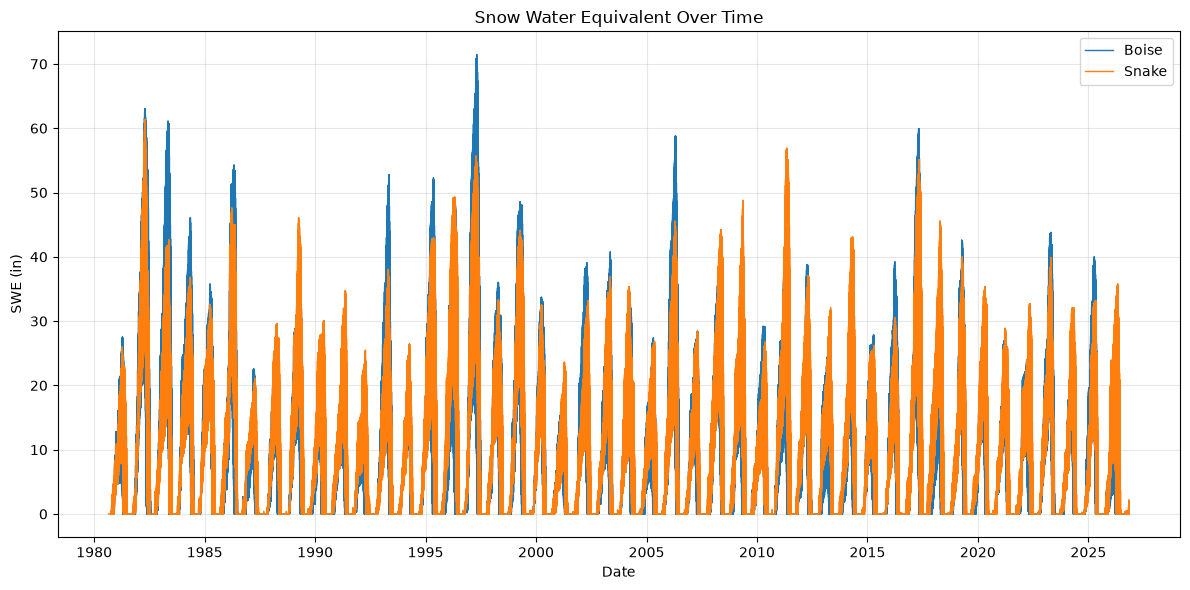

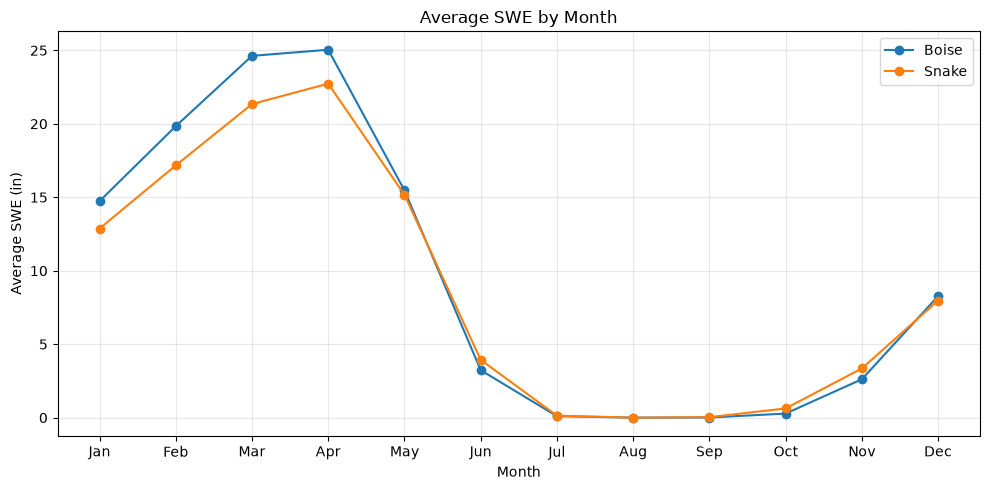

In [10]:
def find_column(frame, candidates):
    # Match column names without worrying about capitalization, spaces, or underscores
    normalize = lambda s: "".join(ch for ch in str(s).casefold() if ch.isalnum())
    columns = {normalize(col): col for col in frame.columns}

    for candidate in candidates:
        match = columns.get(normalize(candidate))
        if match is not None:
            return match

    raise KeyError(
        f"Couldn't find a column matching {candidates}. "
        f"Available columns: {frame.columns.tolist()}"
    )

# Find the date and SWE columns in each dataframe
frames = {"Boise": dfB, "Snake": dfS}
plot_data = {}

for site, data in frames.items():
    date_col = find_column(data, ["Date", "datetime"])
    swe_col = find_column(
        data,
        ["Snow Water Equivalent (in)", "WTEQ", "WTEQ (in)", "SWE", "SWE (in)"]
    )

    cleaned = pd.DataFrame({
        "Date": pd.to_datetime(data[date_col], errors="coerce"),
        "SWE": pd.to_numeric(data[swe_col], errors="coerce")
    }).dropna().sort_values("Date")

    plot_data[site] = cleaned

# Plot 1: SWE over time
fig, ax = plt.subplots(figsize=(12, 6))

for site, data in plot_data.items():
    ax.plot(data["Date"], data["SWE"], label=site, linewidth=1)

ax.set(title="Snow Water Equivalent Over Time", xlabel="Date", ylabel="SWE (in)")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

# Plot 2: Average SWE by month
fig, ax = plt.subplots(figsize=(10, 5))

for site, data in plot_data.items():
    monthly_mean = data.groupby(data["Date"].dt.month)["SWE"].mean()
    ax.plot(monthly_mean.index, monthly_mean.values, marker="o", label=site)

ax.set(
    title="Average SWE by Month",
    xlabel="Month",
    ylabel="Average SWE (in)",
    xticks=range(1, 13),
    xticklabels=["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                 "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

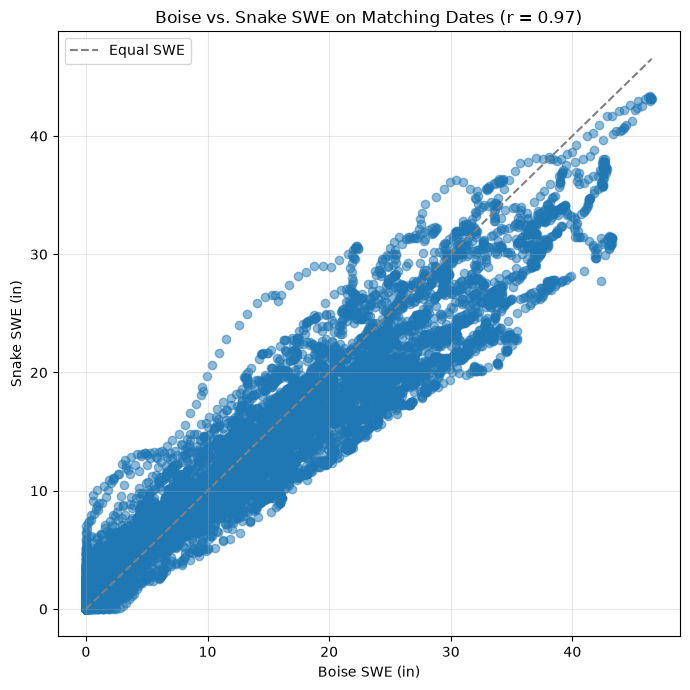

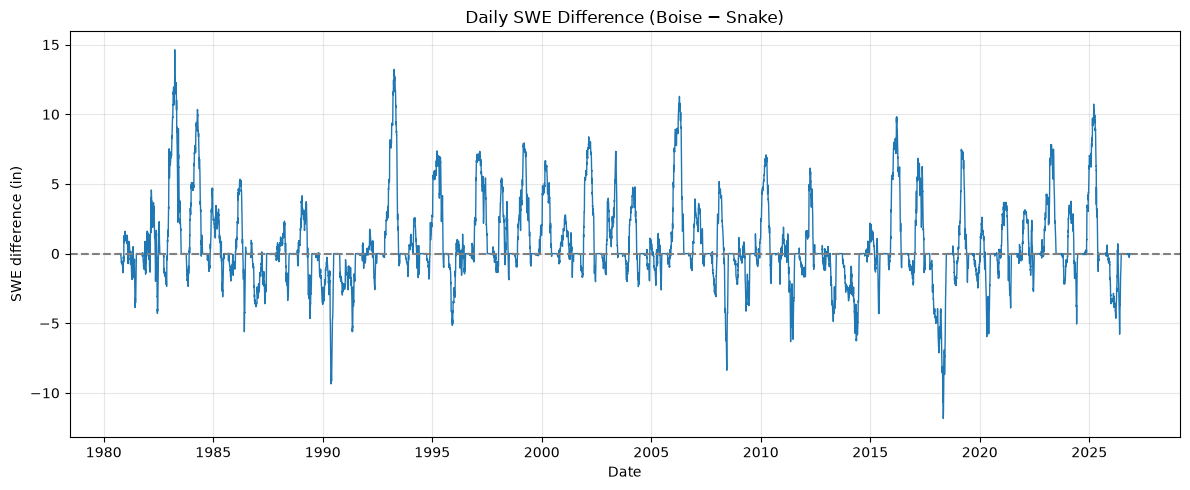

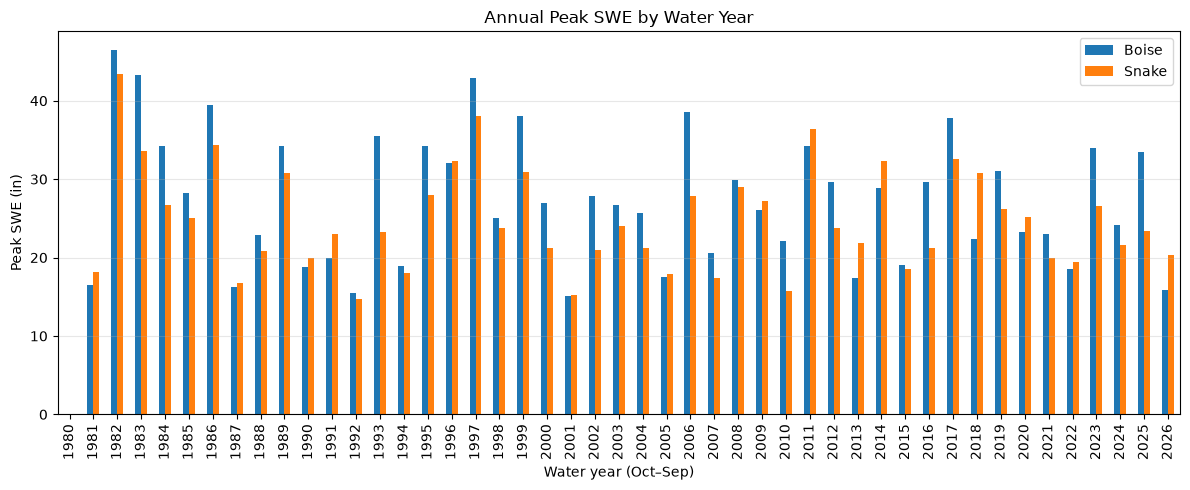

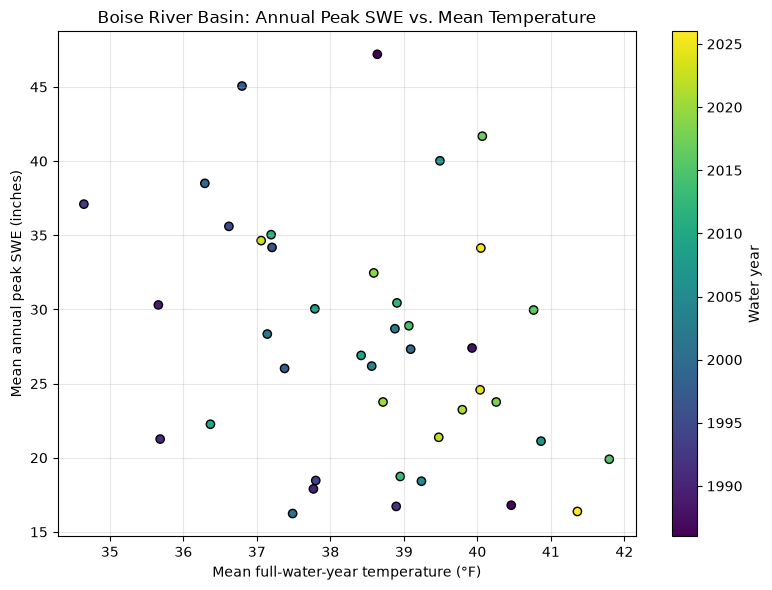

In [18]:
# Build one daily SWE series for each dataset
daily = {}

for site, data in {"Boise": dfB, "Snake": dfS}.items():
    date_col = find_column(data, ["Date", "datetime"])
    swe_col = find_column(
        data,
        ["Snow Water Equivalent (in)", "WTEQ", "WTEQ (in)", "SWE", "SWE (in)"]
    )

    temp = pd.DataFrame({
        "Date": pd.to_datetime(data[date_col], errors="coerce").dt.normalize(),
        site: pd.to_numeric(data[swe_col], errors="coerce")
    }).dropna()

    # Average multiple readings on the same date, if present
    daily[site] = temp.groupby("Date")[site].mean()

comparison = pd.concat(daily, axis=1).dropna()

if comparison.empty:
    raise ValueError("The two datasets have no dates in common to compare.")

# Plot 1: Matched-date SWE comparison
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(comparison["Boise"], comparison["Snake"], alpha=0.5)

limit = max(comparison["Boise"].max(), comparison["Snake"].max())
ax.plot([0, limit], [0, limit], "--", color="gray", label="Equal SWE")
ax.set(
    title=f"Boise vs. Snake SWE on Matching Dates "
          f"(r = {comparison['Boise'].corr(comparison['Snake']):.2f})",
    xlabel="Boise SWE (in)",
    ylabel="Snake SWE (in)"
)
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

# Plot 2: Difference in SWE through time (Boise minus Snake)
fig, ax = plt.subplots(figsize=(12, 5))
difference = comparison["Boise"] - comparison["Snake"]
ax.plot(comparison.index, difference, linewidth=1)

ax.axhline(0, color="gray", linestyle="--")
ax.set(
    title="Daily SWE Difference (Boise − Snake)",
    xlabel="Date",
    ylabel="SWE difference (in)"
)
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

# Plot 3: Compare each water year's peak SWE, excluding WY2027
annual = comparison.copy()
annual["WaterYear"] = annual.index.year + (annual.index.month >= 10)

annual_peaks = (
    annual[annual["WaterYear"] != 2027]
    .groupby("WaterYear")[["Boise", "Snake"]]
    .max()
)

annual_peaks.plot(kind="bar", figsize=(12, 5))
plt.title("Annual Peak SWE by Water Year")
plt.xlabel("Water year (Oct–Sep)")
plt.ylabel("Peak SWE (in)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


for col in ["water_year", "TAVG", "WTEQ"]:
    dfB[col] = pd.to_numeric(dfB[col], errors="coerce")

# Calculate annual mean temperature and peak SWE at each SNOTEL site
by_site_year = (
    dfB.groupby(["site_id", "site_name", "water_year"])
    .agg(
        mean_temp_f=("TAVG", "mean"),
        peak_swe_in=("WTEQ", "max"),
        temp_days=("TAVG", "count"),
        swe_days=("WTEQ", "count"),
    )
    .reset_index()
)

# Keep only site-years with adequate daily data for both measurements
complete = by_site_year[
    (by_site_year["temp_days"] >= 330)
    & (by_site_year["swe_days"] >= 330)
]

# Average the site-level annual values across the Boise basin
annual = (
    complete.groupby("water_year")
    .agg(
        mean_temp_f=("mean_temp_f", "mean"),
        mean_peak_swe_in=("peak_swe_in", "mean"),
    )
    .reset_index()
)

fig, ax = plt.subplots(figsize=(8, 6))

points = ax.scatter(
    annual["mean_temp_f"],
    annual["mean_peak_swe_in"],
    c=annual["water_year"],
    cmap="viridis",
    edgecolors="black",
)

ax.set(
    title="Boise River Basin: Annual Peak SWE vs. Mean Temperature",
    xlabel="Mean full-water-year temperature (°F)",
    ylabel="Mean annual peak SWE (inches)",
)
ax.grid(True, alpha=0.3)

colorbar = fig.colorbar(points, ax=ax)
colorbar.set_label("Water year")

plt.tight_layout()
plt.show()

### Figures using USGS flow data and SNOTEL data. 

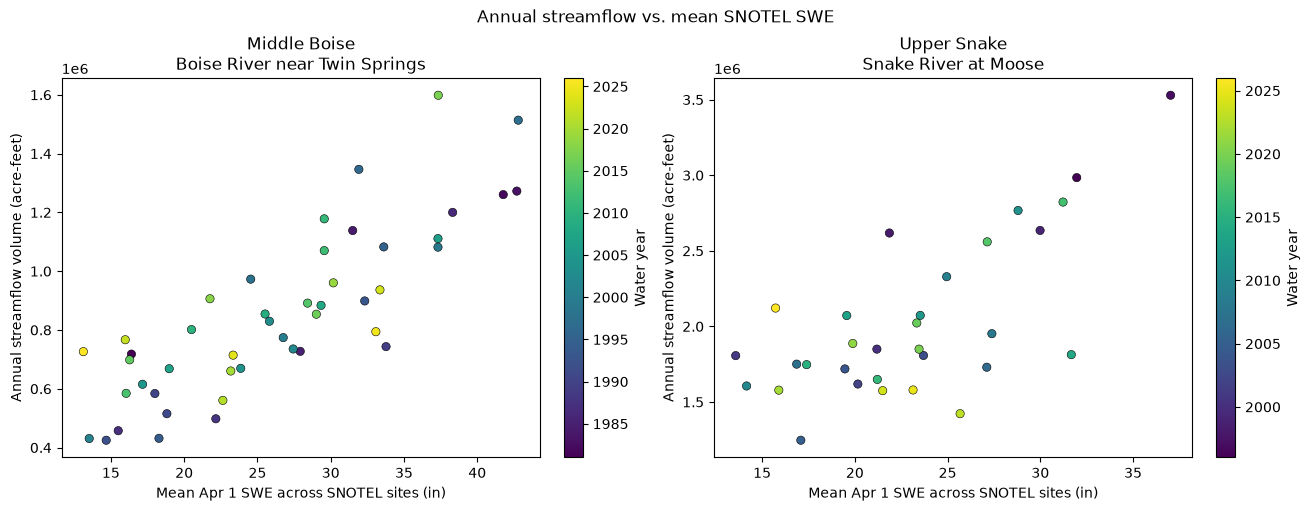

In [16]:
%run annual_flow_vs_swe.py

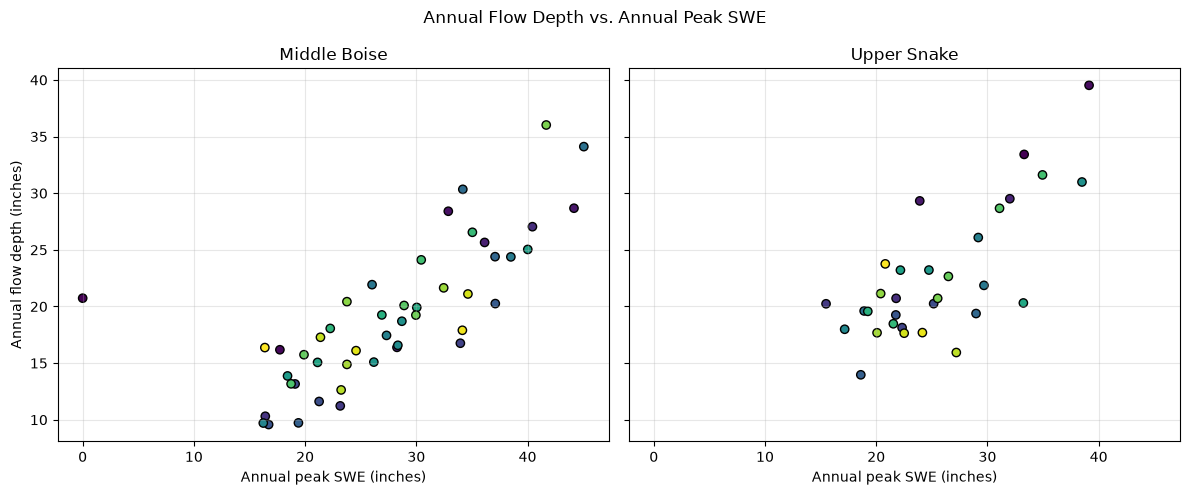

In [20]:
flow = pd.read_csv(
    "Data/usgs_flow_annual_by_water_year.csv",
    dtype={"gage_id": "string"},
)

basins = [
    ("Middle Boise", "Data/snotel_boise_annual_by_water_year.csv", "13185000"),
    ("Upper Snake", "Data/snotel_snake_annual_by_water_year.csv", "13013650"),
]

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

for ax, (name, swe_file, gage_id) in zip(axes, basins):
    swe = pd.read_csv(swe_file)

    # Basin-average annual peak SWE across SNOTEL sites
    swe = swe[swe["days_of_data_in_wy"] >= 330]
    annual_swe = (
        swe.groupby("water_year")["annual_swe_peak_in"]
        .mean()
        .reset_index()
    )

    # Annual flow depth for the matching USGS gage
    annual_flow = flow[
        (flow["gage_id"] == gage_id)
        & (flow["days_of_data_in_wy"] >= 330)
    ][["water_year", "wy_total_flow_in"]]

    # Keep water years with both SWE and flow data
    annual = annual_swe.merge(annual_flow, on="water_year").dropna()

    points = ax.scatter(
        annual["annual_swe_peak_in"],
        annual["wy_total_flow_in"],
        c=annual["water_year"],
        cmap="viridis",
        edgecolors="black",
    )

    ax.set_title(name)
    ax.set_xlabel("Annual peak SWE (inches)")
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel("Annual flow depth (inches)")
fig.suptitle("Annual Flow Depth vs. Annual Peak SWE")
plt.tight_layout()
plt.show()